# Cross-section SOI de 4.8 µm

Resolución modal con FEMWELL de una guía strip con núcleo de silicio, cladding homogéneo de SiO₂ térmico, 4.8 µm de ancho y 220 nm de altura. Todas las dimensiones están expresadas en micrómetros.

In [1]:
from __future__ import annotations

import matplotlib.pyplot as plt
import numpy as np

from upvfab_design_tools.core.materials import (
    SILICON,
    THERMAL_SILICON_DIOXIDE,
)
from upvfab_design_tools.core.visualization import plot_cross_section
from upvfab_design_tools.core.waveguides import strip_waveguide
from upvfab_design_tools.modesolver import FemwellModeSolver
from upvfab_design_tools.modesolver.visualization import (
    plot_effective_indices,
    plot_modes_grid,
)

## Parámetros

In [2]:
WAVELENGTH_UM = 1.55
CORE_WIDTH_UM = 4.8
CORE_HEIGHT_UM = 0.220
NUM_MODES = 12

DOMAIN_X_SPAN_UM = 8.8
BOTTOM_MARGIN_UM = 2.0
TOP_MARGIN_UM = 2.0
MAX_PLOTTED_MODES = 6

## Construcción y visualización de la cross-section

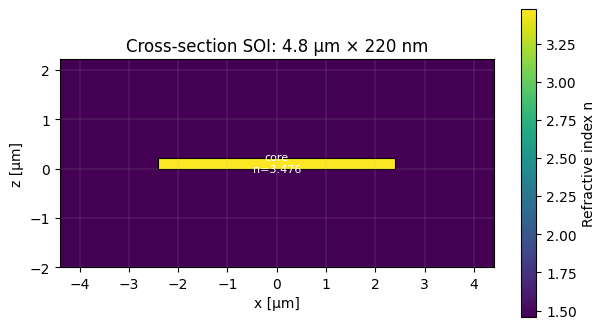

In [3]:
cross_section = strip_waveguide(
    width=CORE_WIDTH_UM,
    height=CORE_HEIGHT_UM,
    core_material=SILICON,
    background_material=THERMAL_SILICON_DIOXIDE,
    x_center=0.0,
    z_min=0.0,
    x_span=DOMAIN_X_SPAN_UM,
    bottom_margin=BOTTOM_MARGIN_UM,
    top_margin=TOP_MARGIN_UM,
    name="soi_strip_4p8um_x_220nm",
)

fig, ax = plot_cross_section(
    cross_section,
    wavelength_um=WAVELENGTH_UM,
    show_names=True,
    show_indices=True,
)
ax.set_title("Cross-section SOI: 4.8 µm × 220 nm")
plt.show()

## Resolución modal con FEMWELL

In [4]:
solver = FemwellModeSolver(
    resolution_overrides={
        "core": {"resolution": 0.03, "distance": 0.25},
        "background": {"resolution": 0.30, "distance": 1.0},
    },
    reference_material=THERMAL_SILICON_DIOXIDE,
    filter_guided=True,
    guided_tolerance=1e-2,
)

print("Resolviendo modos con FEMWELL...", flush=True)
result = solver.solve(
    cross_section,
    wavelength_um=WAVELENGTH_UM,
    num_modes=NUM_MODES,
)

Resolviendo modos con FEMWELL...


## Resultados modales

In [5]:
print(f"Modos guiados encontrados: {len(result)}")
print(" índice |       n_eff | polarización | fracción TE | fracción TM")
print("--------+-------------+--------------+-------------+------------")

for mode in result.modes:
    te_fraction = float("nan") if mode.te_fraction is None else mode.te_fraction
    tm_fraction = float("nan") if mode.tm_fraction is None else mode.tm_fraction
    print(
        f" {mode.index:6d} | {mode.neff.real:11.8f} | "
        f"{mode.polarization:^12s} | {te_fraction:11.6f} | {tm_fraction:10.6f}"
    )

Modos guiados encontrados: 12
 índice |       n_eff | polarización | fracción TE | fracción TM
--------+-------------+--------------+-------------+------------
      0 |  2.84446838 |      TE      |    0.999986 |   0.000014
      1 |  2.83083052 |      TE      |    0.999945 |   0.000055
      2 |  2.80795896 |      TE      |    0.999871 |   0.000129
      3 |  2.77563386 |      TE      |    0.999758 |   0.000242
      4 |  2.73353308 |      TE      |    0.999593 |   0.000407
      5 |  2.68121667 |      TE      |    0.999355 |   0.000645
      6 |  2.61810297 |      TE      |    0.999014 |   0.000986
      7 |  2.54343473 |      TE      |    0.998513 |   0.001487
      8 |  2.45623243 |      TE      |    0.997755 |   0.002245
      9 |  2.35522739 |      TE      |    0.996560 |   0.003440
     10 |  2.23877313 |      TE      |    0.994559 |   0.005441
     11 |  2.10474313 |      TE      |    0.990919 |   0.009081


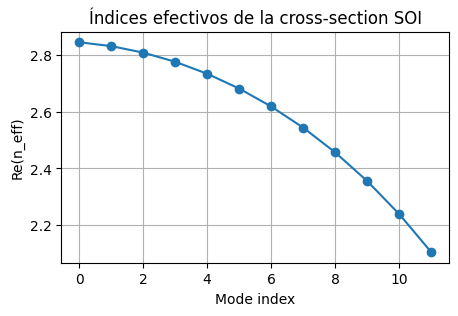

In [6]:
fig, ax = plot_effective_indices(result)
ax.set_title("Índices efectivos de la cross-section SOI")
plt.show()

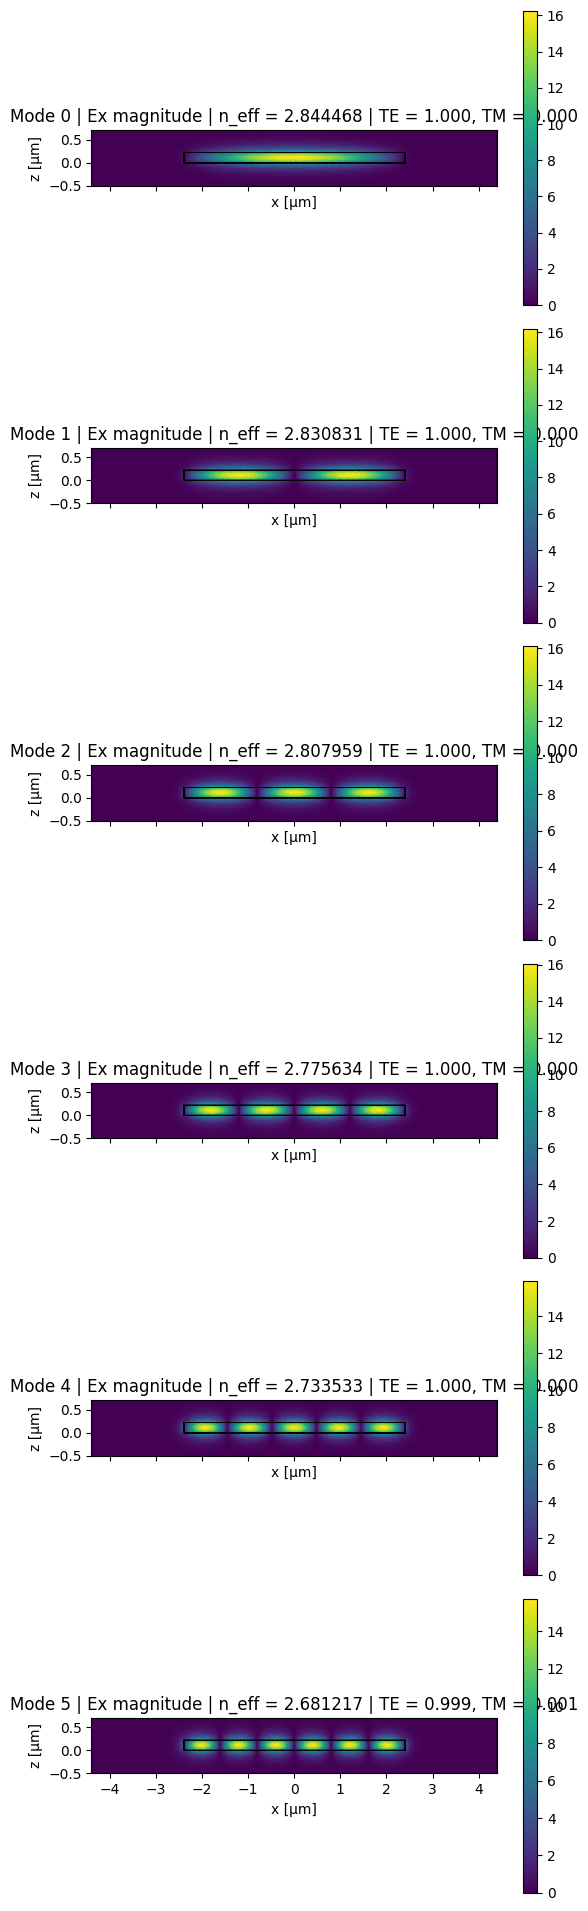

In [7]:
fig, axes = plot_modes_grid(
    result,
    field_component="auto",
    field_part="mag",
    max_modes=MAX_PLOTTED_MODES,
    xlim=(-0.5 * DOMAIN_X_SPAN_UM, 0.5 * DOMAIN_X_SPAN_UM),
    zlim=(-0.5, 0.7),
    show_mesh=True,
)
plt.show()

## Longitud de batido TE

Se calcula con los dos primeros modos TE guiados: $L_{\pi,\mathrm{TE}} = \pi / |\beta_{\mathrm{TE0}} - \beta_{\mathrm{TE1}}|$.

In [8]:
te_modes = result.te_modes
if len(te_modes) < 2:
    raise RuntimeError("Se necesitan al menos dos modos TE guiados para calcular Lpi_TE.")

te0, te1 = te_modes[:2]
beta_te0 = float(np.real(te0.beta))
beta_te1 = float(np.real(te1.beta))
delta_beta_te = abs(beta_te0 - beta_te1)
if delta_beta_te <= 0.0:
    raise RuntimeError("Los dos primeros modos TE tienen la misma constante de propagación.")

lpi_te_um = float(np.pi / delta_beta_te)

print(f"n_eff(TE0) = {te0.neff.real:.8f}")
print(f"n_eff(TE1) = {te1.neff.real:.8f}")
print(f"beta_TE0 = {beta_te0:.8f} rad/um")
print(f"beta_TE1 = {beta_te1:.8f} rad/um")
print(f"Lpi_TE = {lpi_te_um:.6f} um")

n_eff(TE0) = 2.84446838
n_eff(TE1) = 2.83083052
beta_TE0 = 11.53053029 rad/um
beta_TE1 = 11.47524693 rad/um
Lpi_TE = 56.827098 um
